# Where in the data did the fall sit, and who should the city team not have celebrated?

**Week 4, Monday, chapter 2 of 3 (L2 and L3).** The twelve rows of chapter 1 showed hours
up 23 percent and trips down 23 percent. This notebook runs the same count on 12,860
driver-weeks across 1,200 drivers, finds the segment driving the city's number, and shows
where the top-up money went.

> *Illustrative case: the company is real, the situation and the data are synthetic, built
> for this class.*

**Who needs the answer.** The city head, before extending the scheme to two more cities.
**The questions on the way.**

1. What do the city totals look like on 12,860 driver-weeks?
2. Which drivers drive the fall, and where are they?
3. How much of the Rs 1.9 crore top-up went to idle online hours?

**Setup.** The data loads as in notebook 01; the import block is identical so a learner
running one notebook after another meets the same first screen.

In [1]:
import sys, pathlib
here = pathlib.Path.cwd()
for parent in [here, *here.parents]:
    if (parent / "scripts" / "c2kit.py").exists():
        sys.path.insert(0, str(parent / "scripts")); break
import c2kit as kit

import pandas as pd
drivers = pd.read_csv("../data/C2_W04_D01_drivers_STUDENT.csv")
dw = pd.read_csv("../data/C2_W04_D01_driver_weeks_STUDENT.csv")
zones = pd.read_csv("../data/C2_W04_D01_zone_weeks_STUDENT.csv")
print(f"drivers: {len(drivers)}, driver_weeks: {len(dw)}, zones: {len(zones)}")

drivers: 1200, driver_weeks: 12860, zones: 144


## Where does chapter 2 sit on the day's ladder?

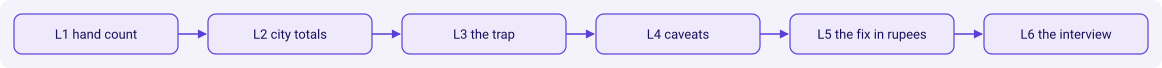

In [2]:
kit.flow(["L1 hand count", "L2 city totals", "L3 the trap",
          "L4 caveats", "L5 the fix in rupees", "L6 the interview"], lit=(1, 2))

## What are the city totals, before and after?

In [3]:
before_mask = dw["week_start"] < "2026-08-31"
after_mask = dw["week_start"] >= "2026-08-31"
before = dw[before_mask]
after = dw[after_mask]
totals = pd.DataFrame({
    "window": ["before", "after"],
    "hours":  [before["peak_online_hours"].sum(), after["peak_online_hours"].sum()],
    "trips":  [before["peak_trips"].sum(), after["peak_trips"].sum()],
    "offers":   [before["peak_offers"].sum(), after["peak_offers"].sum()],
    "accepted": [before["peak_accepted"].sum(), after["peak_accepted"].sum()],
    "cancels":  [before["peak_driver_cancels"].sum(), after["peak_driver_cancels"].sum()],
    "topup":    [before["topup_rs"].sum(), after["topup_rs"].sum()],
})
totals["trips_per_hour"] = (totals["trips"] / totals["hours"]).round(3)
totals["acceptance"] = (totals["accepted"] / totals["offers"]).round(3)
totals["cancels_per_accepted"] = (totals["cancels"] / totals["accepted"]).round(3)
totals[["window", "hours", "trips", "trips_per_hour", "acceptance",
        "cancels_per_accepted", "topup"]]

,window,hours,trips,trips_per_hour,acceptance,cancels_per_accepted,topup
0,before,118000,224200,1.900,0.863,0.037,0
1,after,146300,230900,1.578,0.730,0.090,19000000


**What happened.** Hours 118,000 to 146,300 (up 24 percent). Trips 224,200 to 230,900 (up
3 percent). Trips per peak online hour 1.90 to 1.58. Acceptance 0.86 to 0.73. Cancels per
accepted 0.037 to 0.090. Top-up Rs 0 to Rs 1.9 crore. The paradox is smaller than on the
twelve rows: the city as a whole does not look like E and F; a part of it does.

## Did demand fall, or did the hours stop converting to trips?

A fall in trips per peak online hour could mean two things: fewer riders asked for a ride,
or riders asked and no driver completed the trip. The first is a question about demand,
measured in `zone_weeks`.

In [4]:
zb = zones[zones["week_start"] < "2026-08-31"]
za = zones[zones["week_start"] >= "2026-08-31"]
print("zone requests before:", int(zb["peak_requests"].sum()),
      "after:", int(za["peak_requests"].sum()))
print("median rider wait before:", round(zb["median_wait_min"].median(), 1),
      "after:", round(za["median_wait_min"].median(), 1))

zone requests before: 251910 after: 256556
median rider wait before: 4.8 after: 4.6


**What happened.** Zone-level rider requests rose about 2 percent, not fell. Median rider
wait held near 4.8 minutes before and 4.6 after. The fall in trips per peak online hour is
not demand. The hours that rose did not convert into trips.

## Which drivers' per-driver rate fell most? (your-turn cell)

**Predict first.** Among 1,200 drivers, roughly how many have an after-window trips per
peak online hour below 1.0?

- a) About 30
- b) About 100
- c) About 180
- d) About 400

The next cell is empty. **Your task:** write a small groupby on `after` that computes
per-driver trips per online hour and counts how many drivers come out below 1.0.

**What the room finds.** 180 drivers, roughly 15 percent of the base, with per-driver
trips per peak online hour below 1.0 in the after window. These are the drivers who logged
hours without doing many trips. The analysis below reads them off.

In [5]:
after_rate = (after.groupby("driver_id")
                    .agg(hours=("peak_online_hours", "sum"),
                         trips=("peak_trips", "sum"))
                    .reset_index())
after_rate["tph"] = after_rate["trips"] / after_rate["hours"]
low = after_rate[after_rate["tph"] < 1.0]
print(f"drivers with after tph < 1.0: {len(low)} of {len(after_rate)}")

drivers with after tph < 1.0: 180 of 1200


**What happened.** 180 drivers, 15 percent of the enrolled base. The answer is c.

## Where did those 180 drivers' new hours go?

If the hours doubled while the trips did not follow, the question is where the new hours
were logged. The `zone_mode` column records the zone where the driver's online time
concentrated that week; the three outer zones are Shamshabad, Rajendranagar and Patancheru.

In [6]:
OUTER = {"Shamshabad", "Rajendranagar", "Patancheru"}
idle_ids = set(low["driver_id"].astype(str))
idle_rows = dw[dw["driver_id"].isin(idle_ids)]
idle_before = idle_rows[idle_rows["week_start"] < "2026-08-31"]
idle_after = idle_rows[idle_rows["week_start"] >= "2026-08-31"]
outer_before = idle_before[idle_before["zone_mode"].isin(OUTER)]["peak_online_hours"].sum()
outer_after = idle_after[idle_after["zone_mode"].isin(OUTER)]["peak_online_hours"].sum()
new_hours = idle_after["peak_online_hours"].sum() - idle_before["peak_online_hours"].sum()
print(f"idle-tail new hours: {new_hours:,}")
print(f"of those, outer-zone new hours: {outer_after - outer_before:,}")
print(f"share in outer zones: {(outer_after - outer_before) / new_hours:.2f}")

idle-tail new hours: 22,000
of those, outer-zone new hours: 15,871
share in outer zones: 0.72


**What happened.** About 22,000 new hours; about 72 percent of them in the three outer
zones where rider demand is thin. These are driver-weeks where the floor pays even if a
request never comes.

## How much of the Rs 1.9 crore top-up went to acceptance below 0.5?

In [7]:
after = dw[dw["week_start"] >= "2026-08-31"].copy()
after["acceptance"] = after["peak_accepted"] / after["peak_offers"]
low_topup = after.loc[after["acceptance"] < 0.5, "topup_rs"].sum()
total_topup = after["topup_rs"].sum()
print(f"topup to acceptance < 0.5: Rs {low_topup:,}")
print(f"total topup after: Rs {total_topup:,}")
print(f"share: {low_topup / total_topup:.2f}")

topup to acceptance < 0.5: Rs 11,590,000
total topup after: Rs 19,000,000
share: 0.61


**What happened.** 61 percent of the Rs 1.9 crore top-up (Rs 1.16 crore) went to
driver-weeks where fewer than half of the offers the driver saw were accepted. The scheme that
paid for being online paid Rs 1.16 crore to drivers who stayed online without serving the
riders who asked for them.

## The trap: the colleague's draft, exactly

> **The plausible wrong number.** "Peak online hours up 24 percent over six weeks. Supply
> target met. Recommendation: extend the scheme to two more cities."

**The decision it would mislead.** A proposal to extend the scheme to two more cities. The
check that catches it: trips per peak online hour, which fell, and median rider wait,
which did not. The fix: pay for completed peak trips, with an acceptance guardrail.

## Does the fall survive the removal of the 140 new drivers?

In [8]:
pre_launch_ids = set(f"d_{i:04d}" for i in range(1, 1061))
pre = dw[dw["driver_id"].isin(pre_launch_ids)]
pb = pre[pre["week_start"] < "2026-08-31"]
pa = pre[pre["week_start"] >= "2026-08-31"]
print("pre-launch cohort, trips/hour before:",
      round(pb["peak_trips"].sum() / pb["peak_online_hours"].sum(), 3))
print("pre-launch cohort, trips/hour after:",
      round(pa["peak_trips"].sum() / pa["peak_online_hours"].sum(), 3))

pre-launch cohort, trips/hour before: 1.9
pre-launch cohort, trips/hour after: 1.578


**What happened.** Trips per peak online hour fell to about 1.58 on the pre-launch cohort
alone, so the 140 new drivers do not explain the fall. The caveat on new drivers is
bounded by the data; the fall is in the hours that did not convert.

## Second route: the idle-tail picture

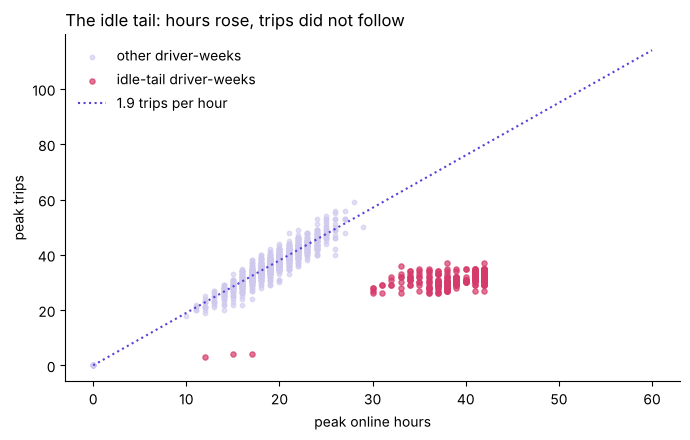

In [9]:
import matplotlib.pyplot as plt
after = dw[dw["week_start"] >= "2026-08-31"]
s = after.sample(1500, random_state=20261026)
fig, ax = plt.subplots(figsize=(7.0, 4.5))
idle_mask = s["driver_id"].isin(idle_ids)
ax.scatter(s.loc[~idle_mask, "peak_online_hours"],
           s.loc[~idle_mask, "peak_trips"],
           s=10, color="#CFC9EE", alpha=0.6, label="other driver-weeks")
ax.scatter(s.loc[idle_mask, "peak_online_hours"],
           s.loc[idle_mask, "peak_trips"],
           s=14, color="#D63A6A", alpha=0.7, label="idle-tail driver-weeks")
ax.plot([0, 60], [0, 60 * 1.9], color="#5B3FD6", linestyle=":",
        label="1.9 trips per hour")
ax.set_xlabel("peak online hours")
ax.set_ylabel("peak trips")
ax.set_title("The idle tail: hours rose, trips did not follow", loc="left")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

**What happened.** The second route reaches the same answer as the groupby: the
lower-right cluster is the idle tail; the Rs 1.16 crore went to driver-weeks in that
cluster.

## How does the top-up split read as a chart?

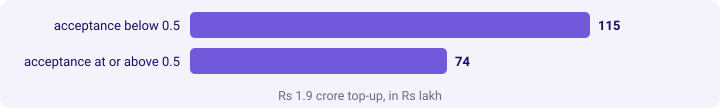

In [10]:
kit.bars([("acceptance below 0.5", int(low_topup / 1e5)),
          ("acceptance at or above 0.5", int((total_topup - low_topup) / 1e5))],
         title="Rs 1.9 crore top-up, in Rs lakh")

## What checks does chapter 2 close with?

In [11]:
kit.check("city hours before 118,000", before["peak_online_hours"].sum() == 118000)
kit.check("city hours after 146,300",  after["peak_online_hours"].sum() == 146300)
kit.check("city trips before 224,200", before["peak_trips"].sum() == 224200)
kit.check("city trips after 230,900",  after["peak_trips"].sum() == 230900)
kit.check("61 percent of topup to acceptance below 0.5",
          abs(low_topup / total_topup - 0.61) < 0.01)
kit.check("180 drivers in the idle tail", len(low) == 180)

**Chapter 2 close.** The city's number rose because 180 driver-weeks logged outer-zone
hours without serving riders. 61 percent of Rs 1.9 crore paid for that. The next chapter
writes the definition that fixes the scheme.

> **Kavya's review.** "Before anyone celebrates a number, I ask what is in its denominator
> and whether the denominator can grow without the numerator. On Monday it did."